## 1. 합성곱 신경망(CNN, Convolutional NN)  

### 픽셀, 채널  

#### 1-0 픽셀과 채널

> 픽셀 : 이미지 데이터를 구성하는 가장 기본적인 단위, 하나의 픽셀은 이미지의 특정 위치에 해당하는 색상 또는 밝기정보를 가지고 있음  

이미지가 흑백일 경우 이미지의 크기는 2차원 배열 (NumPy ndarray = 세로 픽셀수 * 가로 픽셀 수)로 표현  

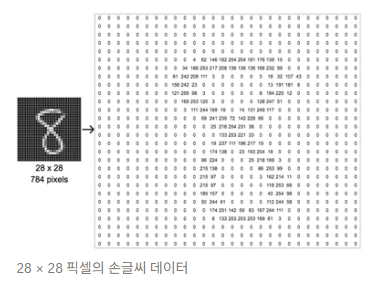  

1. 픽셀 값의 표현 방법

흑백 이미지 : 하나의 픽셀값으로 밝기로 표현(0(검은색) - 255(흰색)) 그 사이 값은 수에 따라 회색으로 표현  

컬러 이미지 : RGB 세가지 색상의 값으로 표현, 각 채널은 컬러와 마찬가지로 0 ~ 255 사이 값을 가지며 이를 조합하여 색상이 표현됨  

2. 채널 : 이미지의 색상정보를 구성하는 각각의 데이터 층, 하나의 이미지에서 밝기정보를 구분하여 저장하는 단위  

3. 색 공간 : 이미지를 구성하는 색상을 숫자로 표현하는 방법이나 체계 - 대표적으로 그레이 스케일(Grayscale), RGB, HSV  

- 그레이 스케일 : 색상의 구분없이 밝기정보만으로 이미지 표현  

    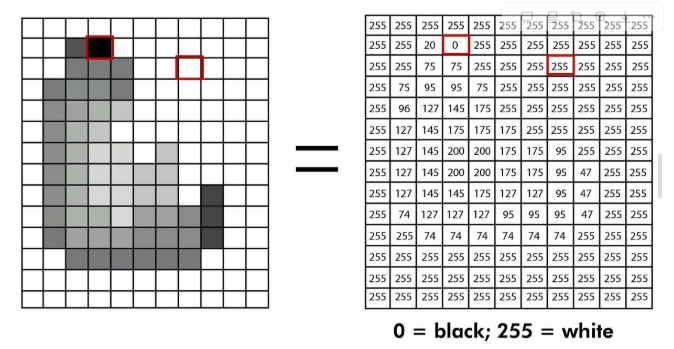  

    0 : 검은색, 128 : 중간정도 회색, 255 : 흰색  
    각 픽셀이 표현하는 정보가 오직 '밝기' 하나 이므로 채널 수가 1  
    -> (28*28*1)의 크기를 가지는 3차원 텐서로 표현  
    *텐서란? 수학과 프로그래밍에서 다차원 데이터 배열을 통칭하는 용어*  

- RGB : RGB 세가지 색상 조합으로 색 표현  
    - 흔히 알고 있는 빛의 삼원색 조합법으로 색 표현, 높이가 28, 너비가 28인 컬러이미지가 있다면 해당 이미지의 텐서는 (28 * 28 * 3)

- HSV : 색상(Hue), 채도(Saturation), 명도(Value)를 기준으로 색 표현  

#### 1-1 CNN개념  

CNN은 왜 필요하게 됐을까?  

컴퓨터와 달리 사람은 모든 픽셀을 하나하나 살펴보면서 물체를 인식하지 않음. 예를 들어, 강아지를 볼 때, 눈, 귀, 코, 꼬리처럼 물체를 구분하는데 중요한 영역과 특징에 집중.  
반면, 컴퓨터는 이미지를 픽셀단위로 구분하여, 각 픽셀에 저장된 색상과 밝기등의 숫자정보를 처리하여 인식  

이미지를 1차원으로 펼쳐서 학습하면 원래 이미지가 가지고 있떤 2차원 공간 정보가 사라짐 -> 학습이 어려워짐  

**MLP VS CNN**  

MLP = FC layer + ... + FC layer  / CNN = (Conv + Pool) + ... + Flatten + FC Layer + ... + FC Layer  

- MLP는 입력된 데이터를 FC Layer에 전달하여 학습하는 구조  
- CNN은 이미지의 공간적 특징을 유지하면서 Conv와 Pool을 반복하여 이미지의 특징을 추출, 이후 Flatten을 통해 추출된 특징을 1차원으로 변환하고, FC layer을 적용하여 이미지를 분류  

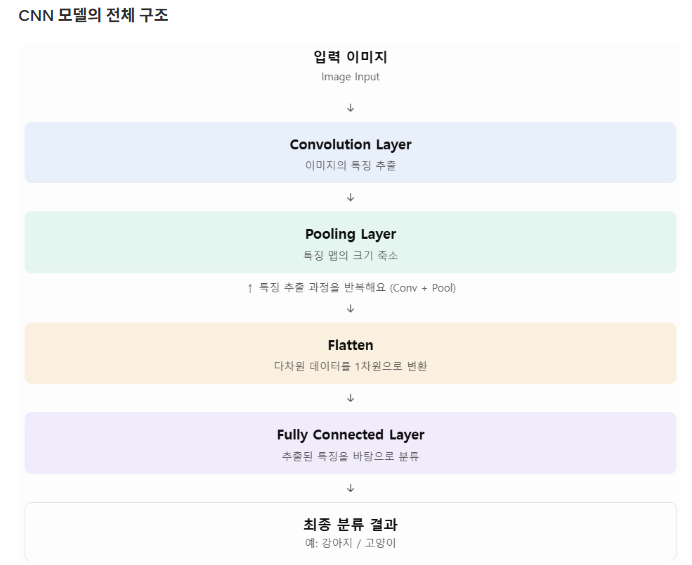  

-> 둘의 가장 큰 차이점은 CNN이 FC Layer를 적용하기 전 Conv와 Pool을 이용하여 이미지의 특징을 학습하는 과정이 추가  

- 특징 추출(Feature Learning)  
    - Convolution Layer : 필터(Kernel)를 이미지 위에서 이동시키며 모서리, 질감, 형태 등 이미지의 다양한 특징을 추출  

    - Pooling Layer : 추출된 특징 맵의 크기를 줄이고 중요한 특징을 유지하여 연산량을 감소시킴  

- Flatten : 여러 차원으로 이루어진 특정 맵을 FC Layer에 입력할 수 있도록 1차원 배열로 변환   

- 분류(Classification)  
    - Fully Connected Layer : 추출된 특징들을 종합하여 이미지가 어떤 클래스에 속하는지 최종적으로 분류  

-> 이미지를 인식하기 위한 모델은 이미지읱 특징을 **학습하는 부분**과 학습한 특징을 바탕으로 어떤 이미지인지 **분류하는 부분**으로 구성  


#### 1-2 그렇다면 왜 이미지 처리에 MLP가 아닌 CNN을 사용?   

MLP는 이미지를 1차원 배열로 펼쳐서 입력받고, 각 픽셀 위치에 해당하는 가중치를 학습 But, 앞서 언급한것과 같이 1차원 배열의 경우 문제가 발생!  

Why? -> 이미지는 픽셀들이 가로와 세로 방향으로 연결되어 있으며, 주변 픽셀 간의 관계와 위치정보가 중요하기 떄문  
픽셀간의 공간적 관계와 이미지의 구조를 유지하면서 특징을 학습할 수 있는 모델이 바로 CNN!  

CNN에서는 Convolution을 통해 이미지의 특정한 특징을 추출하고, 이후 Pooling을 통해 맵의 크기를 줄이는 과정을 통해 작은 위치 변화에도 비슷한 특징을 유지할수 있도록 함  
-> 특징이 어느 픽셀 위치에 있는지 보는것뿐만 아니라 이미지 안에 해당 특징이 존재하는지 효과적으로 학습 가능  


#### 1-3 합성곱(Convolution)과 풀링(Pooling)  

1. > Convolution Layer : 입력 이미지 전체를 일정한 크기의 필터로 훑으면서 이미지의 특징을 추출하고 학습하는 계층  

필터를 적용하여 연산을 수행하고, 그 결과를 새로운 데이터로 만들어 냄, 이때 필터는 수직서느 수평선, 모서리, 질감 등과 같은 이미지의 특정한 패턴이나 특징을 감지하는 역할을 수행  

- 연산 과정  
    1. 필터가 이미지 위를 슬라이딩  
        - 작은 크기의 필터를 입력 이미지 좌상단에 배치  
        - 이후 정해진 간격만큼 오른쪽으로 이동하며 이미지의 각 영역을 확인  
        - 한 행의 연산이 끝나면 다음 행으로 이동하여 반복  

    2. 각 위치에서 요소별 곱셈 후 합계 계산  
        - 필터가 위치한 영역의 픽셀값과 필터의 가중치를 각각 같은 위치끼리 곱함  
        - 곱한 결과를 모두 더하여 하나의 숫자를 계산  
    
    3. 결과를 Feature Map에 저장  
        - 한 위치에서 계산된 결과값을 Feature Map의 해당 위치에 저장  
        - 필터가 모든 위치에서 연산을 마치면 하나의 Feature Map이 완성  
        *Feature Map이란? Convolutiom 연산을 통해 생성되는 결과 데이터로서 필터가 특정 특징에 반응할수록 해당 위치의 Feature Map의 값이 커짐*  


2. > Padding : Convolution 연산을 수행하기 전에 입력 이미지의 가장자리에 추가적인 픽셀을 삽입하는 방법  

필터는 입력 이미지 범위 안에서만 이동하기 때문에 Padding을 적용하지 않으면 가장 자리 영역은 필터가 적용되는 횟수가 상대적으로 적게됨. 이러한 문제를 보완하고 Feature Map의 크기를 조절하는 역할을 하는것이 Padding!  

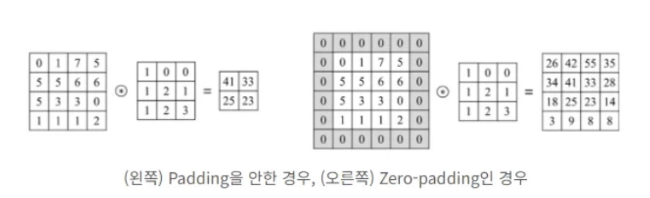  

즉 Padding은 이미지의 공간적 크기를 유지하며 가장자리의 특징까지 학습할 수 있도록 하는 역할  


3. > Stride(보폭) : 필터가 옆으로 이동하는 보폭  
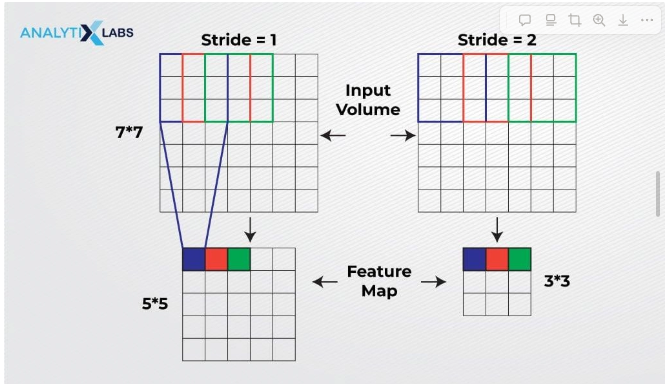  

- Stride = 1  
    - 한 칸씩 이동하여 이미지의 여러 위치를 세밀하게 확인하고, Feature Map의 크기가 상대적으로 크다  

- Stride = 2  
    - 두 칸씩 이동하여 일부 위치를 건너띄며 연산하고, Feature Map의 크기가 상대적으로 작다  

즉. Stride가 커질수록 필터가 한번에 이동하는 거리가 늘어나므로 입력 이미지에서 연산하는 위치는 줄어들고 Feature Map의 크기도 작아짐    
-**특징을 얼마나 세밀하게 추출하고, 연산효율을 어떻게 조절할지 결정하는 요소**  

4. > Pooling : 이미지의 작은 위치 변화에 대한 민감도를 낮추어 모델이 특징을 더 안정적으로 인식할 수 있도록 도와줌  

- 일정한 크기의 영역을 설정하고, 해당 영역에 포함된 값들을 하나의 값으로 요약  
- 일반적으로 2*2 크기의 영역 사용, 각 영역에서의 최댓값(Max Pooling)이나 평균값(Average Pooling)을 계산하는 방식  
- Pooling을 통해 이미지의 공간적 크기를 축소하고, 이후 단계에서 처리해야 하는 데이터의 양을 줄일 수 있음..  

**Pooling을 적용하지 않으면?**  
Pooling을 사용하지 않고 합성곱만 거치게 되면 필터는 엄격하게 특정한 픽셀 위치에서만 해당 패턴을 찾으려고만 함. 이 경우, 이미지 속 객체의 위치나 내부요소가 이동하게 되면 필터가 반응하는 위치가 어긋나면서 모델은 이를 특징으로 인식하지 못하는 문제 발생!  

**Pooling의 장단점**  
- 장점 
    1. 차원 축소로 계산량 감소  
    - Feature Map의 가로, 세로 크기를 줄여 이후 계층의 연산 부담 완화  

    2. 위치 변화에 대한 강건성  
    - 주변 영역의 값을 요약하기 때문에 작은 위치 변화에도 비슷한 특징 유지 가능  

    3. 과적합 방지에 도움  
    - 불필요한 세부 정보와 공간적 복잡성을 줄여 모델이 특정 위치에 지나치게 의존하는 현상 완화하는데 도움을 줌  

    4. 노이즈 영향 완화  
    - 작은 값들이 주변의 강한 특징에 비해 상대적으로 적게 반영  

- 단점  
    1. 정보 소실의 위험  
    - Feature Map의 크기를 줄이는 과정에서 일부 정보 소실 가능  

    2. 정확한 위치 정보 감소  
    - 객채의 경계나 세밀한 위치정보가 중요한 작업의 경우 Pooling으로 인한 정보손실 가능성 존재  

#### 1-4 대표적인 CNN Arichitecture  

1. AlexNet : 대규모 이미지 데이터를 활용해 이미지의 특징을 직접 학습하고 뷴류하는 딥러닝의 가능성을 보여준 모델  

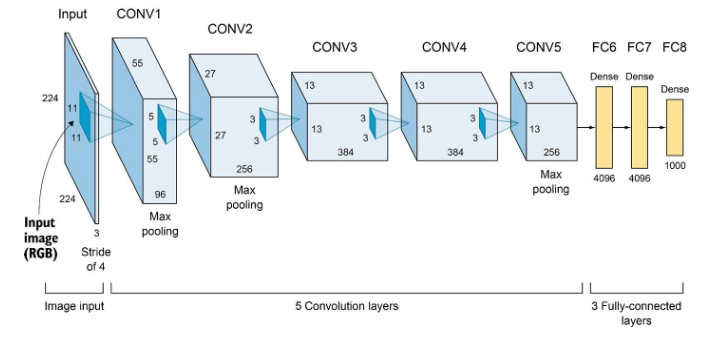  


- 구조
    - Convolution Layer 5개 + Fully Connected Layer 3개 = 총 8개의 학습 계층으로 구성  
    - Convolution Layer 에서 이미지의 특징을 추출하고, 마지막 Fully Connected Layer에서 이미지의 클래스 분류  
    - ReLU, Max Pooling적용

- 특징  
    - ReLU 활성화 함수 도입 : 기존의 tanh대신 ReLU를 도입하여 기울기 소실 문제 해결  
    - 다중 GPU 병렬 연산 : 당시 부족했던 GPU용량을 병렬로 연결하여 네트워크 구조를 상,하단으로 분할해 학습  
    - 드롭아웃(Dropout) : 과적합을 막기 위해 훈련과정에서 완전연결 계층의 뉴런 중 일부를 무작위로 끄고 학습  
    - 데이터 증강 : 이미지를 무작위로 잘라내거나, 좌우 반전, RGB채널값 변경(PCA 이용)을 통해 인위적으로 훈련 데이터를 대폭 증가  
    - 로컬 응답 정규화(LRN) : 측면 억제(Lateral Inhibition) 개념을 모델에 적용해 강하게 활성화된 뉴런 주변을 감쇠  


2. VGGNET : 네트워크 깊이를 늘리면 이미지 인식 성능이 향상될 수 있다는 점을 보여준 모델  

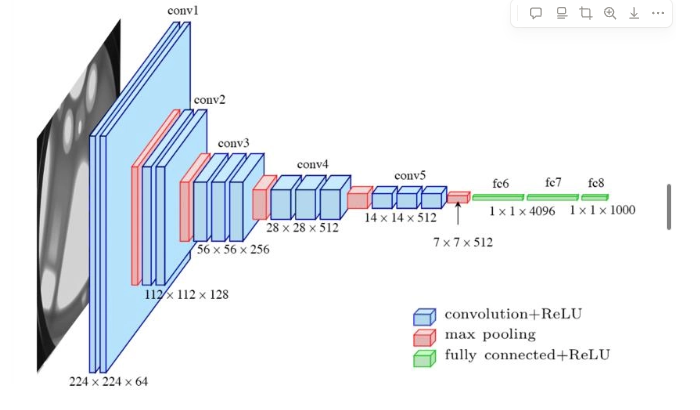  


- 구조  
    - Convolution Layer 13개 + Fully Connected Layer 3개 = 총 16개의 학습 계층으로 구성  
    - 작은 크기의 3 × 3 필터를 반복적으로 적용하고, 중간중간 Max Pooling을 사용 
    - 여러 Convolution Layer를 쌓아 이미지의 특징을 단계적으로 추출  

- 특징  
    - 작은 필터의 반복 사용: 3 × 3 크기의 작은 필터를 여러 번 적용해 다양한 특징을 학습
    - 깊은 네트워크: AlexNet보다 더 많은 계층을 쌓아 복잡하고 추상적인 이미지 특징을 학습 
    - 일관된 구조: 대부분의 Convolution Layer에서 동일한 3 × 3 필터를 사용하여 구조가 비교적 단순하고 이해하기 쉬움
  
- AlexNet 대비 발전한 점  
    - AlexNet은 비교적 큰 필터와 적은 수의 Convolution Layer를 사용하는 점에 비해 VGGNet은 3 × 3 크기의 작은 필터를 반복적으로 적용하고 네트워크를 더 깊게 구성   
    -> 이를 통해 이미지의 단순한 특징부터 복잡한 형태까지 더욱 세밀하게 학습할 수 있도록 발전  


3. ResNET : 깊은 신경망을 효과적으로 학습하기 위해 개발된 모델, 기존 신경망의 단순한 계층 연결 방식에서 벗어나 잔차연결(Residual Connection)이라는 구조 도입   

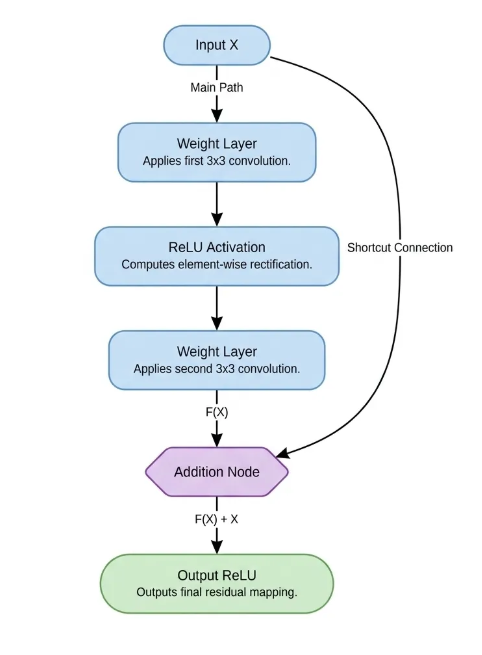   


- **구조 - 핵심 혁신 기술 : 잔차 학습(Residual Learning)과 지름길(Shortcut)**   
    - 여러 개의 Convolution Layer 사이에 Skip Connection을 추가한 구조  
    - Skip Connection은 입력 정보를 중간 계층을 거치지 않고 뒤쪽 계층으로 직접 전달하는 연결 방식  
    - 기존의 계층을 통과한 결과와 처음 입력된 정보를 더해 다음 계층으로 전달  



## 이미지 딥러닝 응용  

### 2-1 이미지 분류(Image Classification)  

> 이미지 분류 모델 : 이미지를 수치 데이터(픽셀 값)로 인식 -> 사전 정의된 클래스 중 하나로 분류  

| 모델명 | 특징 요약 | 주의사항 |
| --- | --- | --- |
| **AlexNet** | 비교적 단순한 구조, 초기 CNN 모델들 | 작은 데이터셋이나 학습 개념 설명용으로 적절 |
| **VGG** | 더 깊은 구조, 복잡한 블록 구조 적용 | 계산량 증대, 메모리 요구 높음 |
| **ResNet** | Residual 연결 (skip connections) → 매우 깊은 네트워크 가능 | 과적합 주의, batch size / regularization 조절 필요 |
| **Vision Transformer (ViT)** | Transformer 구조 응용 → 패치 기반 입력 처리 | 이미지와 순차 처리 모델의 결합, 대규모 데이터 필요 |  

**ViT(Vision Transformer)**
- 이미지를 작은 패치(Patch) 단위로 나누고, 이를 Transformer에 입력하여 이미지의 특징을 학습하는 모델, CNN처럼 필터를 반복적으로 적용하는 대신 Attention을 활용해 이미지 패치 간의 관계를 학습  

- CNN의 확장 가능성  
    - YOLO(You Only Look Once) : 이미지 안의 사람, 자동차 자전거 등을 각각 탐지하고, 객체의 종류와 위치를 동시에 예측  

    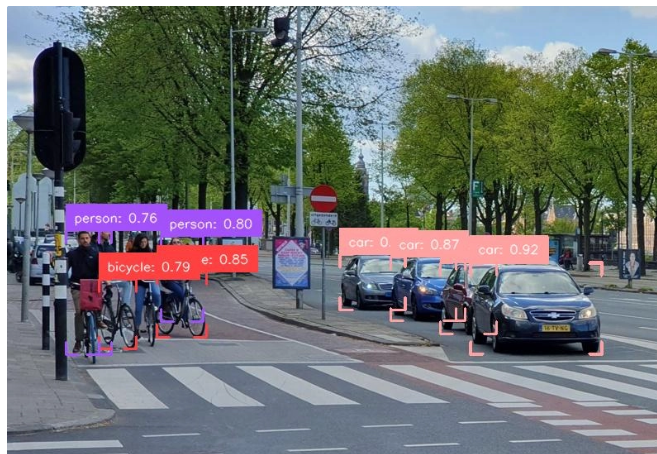  


### 2-2 객체 탐지(Object Detection)  

> 객체 탐지 : 이미지 안에 있는 개별 객체의 종류와 위치를 함께 예측(이미지 분류에서 확장) e.g. Bounding BOX  

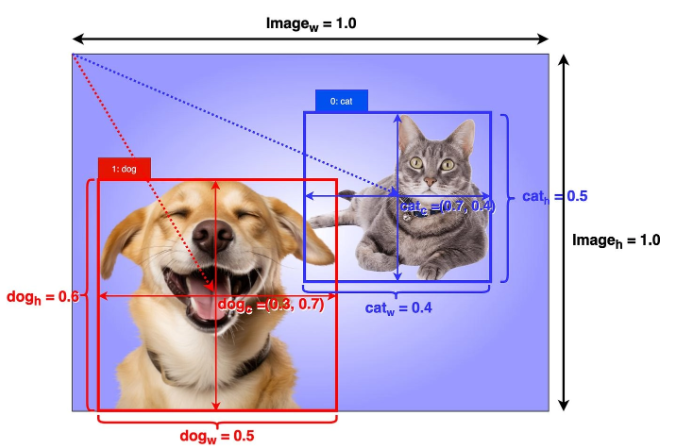  

- Bounding BOX는 이미지에서 객체가 위치한 영역을 둘러싸는 사각형  
- 객체 탐지 모델은 해당 사각형의 위치와 크기를 예측하여 이미지 안에서 객체가 어디있는 지 표시 -> 일반적으로 중심좌표(x,y), 너비(w), 높이(h)를 이용하여 위치 표현  

- 모델 적용 방식 : CNN으로 Feature Map을 얻고 그 위에 두개의 head를 올리는 구조  
    - Classification Head : 객체의 종류 예측  
        -> 이미지에서 탐지한 객체가 어떤 종류(사람, 자동차, 강아지)에 속하는지 판단  
    - Regression Head : 객체의 위치 좌표 예측  
        -> 객체를 둘러싸는 Bounding BOX의 위치와 크기를 예측, 중심 좌표와 너비, 높이등을 계산하여 객체가 이미지의 어느 위치에 있는지 표시  


### 2-3 이미지 캡셔닝(Image Captioning)  

> 이미지 캡셔닝 : 이미지늬 내용을 자연어 문장으로 표현하는 작업, 이미지 특징을 추출하는 CNN과 문장을 생성하는 RNN을 같이 사용  
e.g. 이미지 속에서 사람, 자전거, 도로 라는 객체를 각각 찾아내는것에서 끝이 아닌, '사람이 자전거를 타고 있다'와 같은 객체간의 관계와 행동까지 파악하여 문장으로 표현  

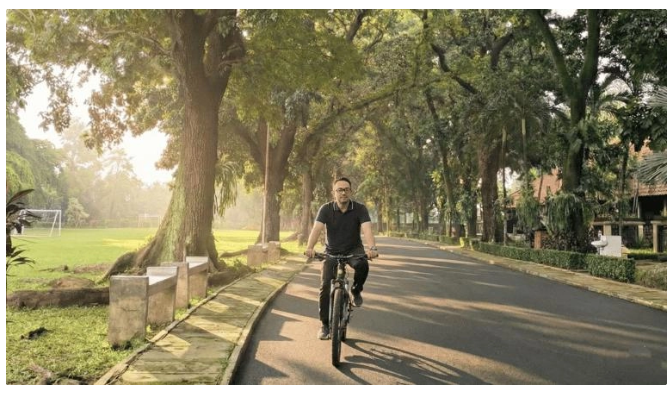  

-> 해당 이미지를 보고 : '한 사람이 도로에서 자전거를 타고 있다'와 같은 객체와 관계 표현!  

- 모델 적용 방식 : CNN, RNN  
    - CNN : 이미지 특징 추출 : 이미지에서 사람, 자전거, 도로와 같은 객체 및 시각적 특징을 추출  
    - RNN : 문장 생성 : CNN이 추출한 이미지를 바탕으로 단어를 순서대로 생성, 이전에 생성한 단어 정보를 활용하여 다음에 올 단어를 예측하고 하나의 문장 완성   



## 신경망(RNN : Recurrent Neural Network)  

### 3-1 순차(Sequence) 데이터  

> 순차 데이터란? 순서가 의미를 갖는 데이터로, 순서를 바꾸면 정보가 달라지는 데이터  

- 순차 데이터 세부 분류  
1. 순서의 기준  

| 구분 | 시간적 순차 데이터 | 비시간적 순차 데이터 |
| --- | --- | --- |
| 기준 | 시간 순 | 시간 외 기준 (위치, 순번) |
| 예시 | 주가, 기온 | 문장 내 단어, DNA 염기서열 |  

2. 자료형  

| 구분 | 수치형 | 범주형 |
| --- | --- | --- |
| 특징 | 값의 크기와 거리에 의미 O | 값의 크기와 거리에 의미 X |
| 예시 | 음성, 비디오 | 웹 클릭 로그, 구매 이력 |  


**기존 정형 데이터 vs 순차 데이터**  

| 비교 관점 | 정형 데이터 | 순차 데이터 |
| --- | --- | --- |
| 순서를 섞으면? | 의미 그대로  | 의미가 달라짐 → **요소의 순서의존성**|
| 샘플 간 관계 | 상호독립적 | 상호의존적
 → 이전 시점/순번이 현재 시점/순번에 영향
→ **자기상관성** |
| 예시 | 고객 정보 데이터 | 주가, 문장 |  

정형 데이터는 고객 A, B, C 행순서를 C, A, B로 바꿔도 의미 변화가 없는 반면, 순차 데이터 : "개가 사람을 물었다" → "사람이 개를 물었다"가 각각 완전히 다른 의미

즉, 기존 머신러닝 기법(회귀, 결정트리, SVM)은 정형 데이터를 전제로 설계되어서 순차 데이터를 처리하는 데는 한계가 존재! -> 순차 데이터를 처리할 별도의 모델이 필요  

**RNN**이 해결책  


### 3-2 RNN(Recurrent Neural Network)  

1. 구조 : 기존신경망과 달리 은닉층에 순환구조가 존재  

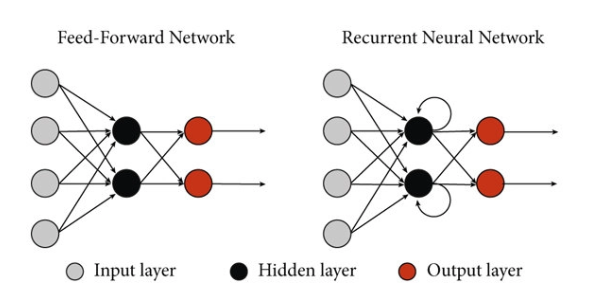  

2. 원리 : 매 시점마다 현재 시점 입력값과 이전 시점 은닉상태를 이용해 현재의 은닉상태를 계산하고 그 결과를 다음 시점으로 넘김.  

예시 : "나는 / 밥을 / 먹었다"  처리과정  

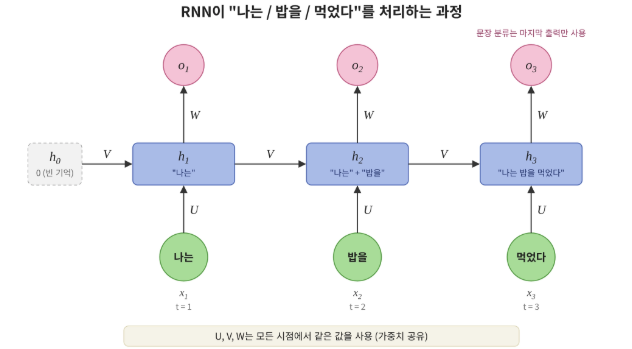  

- t = 1 : '나는' 입력값 처리, 은닉상태로 다음상태 은닉층에 값 전달  
- t = 2 : '나는' + '밥을' 정보 저장  
- t = 3 : 문장 전체 맥락이 마지막 은닉층에 저장되고, 활성화 함수를 거져 최종 출력  

#### RNN 아키텍쳐  
- One to Many - 하나의 입력에서 시퀀스 출력  
    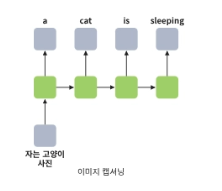  

    - 이미지 캡셔닝에 사용 -> 사진 첫 시점에 한 번만 넣으면 은닉 상태를 거치며 사진의 제목을 출력하는 기능  

- Many to One - 시퀀스 입력에서 하나의 값 출력  
    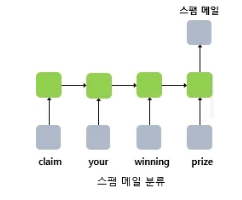  

    - 스팸 메일 분류  
        - 문장을 순차적으로 읽은 후 스팸메일인지 아닌지 판별  

    - 감성 분류  
        - 문장을 순차적으로 읽은 후 감성을 판별   
        - 이진 감성 분류 - 긍정/부정  
        - 다중 감성 분류 - 기쁨/분노/슬품/ 놀람  
    
    - 전체 문장을 읽은 후 최종 판별  

- Many to Many - 시퀀스 입력에서 시퀀스 출력  
    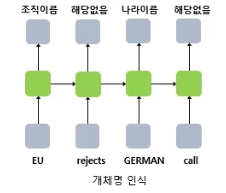  

    - 동기식 Many to Many - 매 시점마다 즉각 출력  
        - 객체 태깅 등에 활용  
    - 비동기식 Many to Many - 전체 입력을 끝까지 읽은 뒤 한 번에 출력  
        - 기계 번역, 요약등에 활용  


### 3-3 RNN의 한계 및 장기 의존성 문제

#### RNN의 한계점  

1. 시간에 따른 역전파 구조  

2. 기울기 소실 : 역전파 과정에서 기울기가 과거 시점으로 갈수록 점점 작에서 0에 수렴하는 현상  

3. 기울기 폭주(Exploding Gradients) : 역전파 과정에서 기울기가 과거 시점으로 갈수록 점점 커져 매우 큰값이 되는 현상 (<-> 기울기 소실)  

4. 느린 훈련 시간 : RNN은 시점을 하나씩 순서대로만 계산할 수 있어서 시퀀스가 길수록 학습에 시간이 오래 소요  

- 특징  
    - 시퀀스 길이에 비례해 계산 시간 증가  
    - 역전파를 위해 모든 시점의 은닉상태를 저장해야 해서 메모리 부담 증가  

- CNN과의 차이점  
    - CNN : 필터가 각 위치를 독립적으로 계산 -> 여러 위치를 동시에 처리 가능  
    - RNN : 앞 시점 결과가 있어야 다음 계산 가능  

-> 시퀀스가 길어질수록 앞부분의 맥락을 뒷부분이 알게하는데 많은 학습 비용 소모  


#### 장기 의존성 문제  

| 한계 | 무슨 일이 일어나나 | 결과 |
| --- | --- | --- |
| 기울기 소실 | 먼 과거로 갈수록 학습 신호가 0에 가까워짐 | 먼 과거 정보 반영 안 됨 |
| 기울기 폭주 | 먼 과거로 갈수록 신호가 폭발해 학습이 불안정 | 먼 관계를 안정적으로 학습하지 못함 |
| 느린 훈련 시간 | 시퀀스가 길어질수록 학습 비용 증가 | 먼 관계를 학습하기 위해서는 많은 학습비용이 필요 |  

**=> 장기 의존성 문제(Long-Term Dependency Problem) : 시퀀스에서 관련된 정보가 멀리 떨어져 있을수록, RNN이 그 관계를 기억하고 학습하지 못하는 문제**  발생  

**Then How? 중요한 정보는 잊지 않고 오래 기억하고, 불필요한 정보는 잊는 메모리 구조 필요 -> LSTM & GRU !**  


## 4. 똑똑하게 기억하고 잊는 법 : LSTM & GRU  

### 4-1 LSTM & GRU  

두 모델 모두 게이트를 활용해 무엇을 기억하고 무엇을 기억하지 않을지 결정  

> 1. LSTM(Long Short-Term Meomory) : 기억을 두개의 상태로 나눠서 관리  

| 구분 | 역할 |
| --- | --- |
| 셀 상태 (Cell State, c) | 장기 기억 |
| 은닉 상태 (Hidden State, h) | 단기 기억 & 출력 |  

-> 기존 RNN은 은닉 상태 h 하나에 모든 걸 덮어썼지만, LSTM은 오래 남길 기억(셀 상태)을 따로 지정  

- 3개의 게이트  
1. Forget Gate : 장기 기억에서 더 이상 필요없는 내용을 삭제  

2. Input Gate : 새로 들어온 정보 중 중요한 것만 장기기억에 저장  

3. Output Gate : 장기기억 중 지금 필요한 부분만 꺼내 단기기억으로 보냄  

- 정리  
    - 장기기억과 단기 기억을 분리해서 관리 -> 정보를 정교하게 다룰 수 있음  
    - 대신 게이트 3개 + 상태 2개 -> 구조가 복잡하고 계산량 많음   


> 2. GRU(Gated Recurrent Unit) : 기억을 하나로 통합해서 관리    
셀 상태와 은닉상태로 나누지 않고, 은닉상태 h하나에 기억과 출력을 모두 포함  

- 2개의 게이트  
1. Update Gate : 과거기억 : 새 정보 = 몇 : 몇 (수치)  
    - *e.g. 과거 70 : 새 정보 30 으로 섞기*  
    - LSTM의 Forget Gate + Input Gate를 게이트 하나로 처리  

2. Reset Gate : 과거의 기억을 얼마나 무시할 것인지  
    - 새 정보를 해석할 때 과거 기억을 얼마나 참고할지(무시할지) 결정  

- 정리  
    - 게이트 2개 + 상태 1개 -> LSTM보다 단순하고 계산이 빠름  
    - 기억을 세밀하게 나누지 않아 정교함은 상대적으로 약함  


### 4-2 게이트로 정보의 흐름을 제어하다 : LSTM  

1. LSTM의 구조  
- 셀 상태(Cell State - 장기기억) : 구조도 맨 위를 가로지르는 선 -> 시점을 따라 이어짐  
    - 정보가 큰 변화 없이 다음 시점으로 흐름  
    - 게이트가 정보를 잊거나 기억하는것을 조절  


2.  LSTM 수식

- Step1. Forget gate : '무엇을 잊을까?'  
    $f_t = \sigma (W_f \cdot[h_{t-1},x+t] + b_f)$  
    $f_t \approx 1 : 그대로 유지 / f_t \approx 0 : 완전히 잊음$  

- Step2. Input gate : '무엇을 새로 기억할까?'  
    $i_t = \sigma (W_i \cdot[h_{t-1},x+t] + b_i)$ : 새 정보를 얼마나 반영할지 (0 ~ 1)  
    $\tilde{C}_t = tanh(W_c \cdot [h_{t-1},x_t] + b_C$ : 추가할 후보 정보(-1 ~ 1)  
    *후보정보 : 이번 시점에 새로 기억할 수도 있는 정보의 후보*  
    - 실제로 더해지는 양 = $i_t = \odot \tilde{C}_t$  

- Step3. Final memory cell : '기억 업데이트'  
    - $C_t = f_t \odot C_{t-1} + i_t \odot \tilde{C}_t$   
    - step 1에서 남긴 이전기억 + step2에서 고른 새 정보  
    - 곱셈이 아닌 덧셈  

- Step4. Output : '무엇을 내보낼까?'  
    $o_t = \sigma (W_o \cdot [h_{t-1},x_t] + b_o)$ : 셀 상태 중 어느 부분을 내보낼지 (0 ~ 1)  
    $h_t = o_t \odot tanh(C_t)$ : 셀 상태를 -1 ~ 1로 정리한 뒤 필요한 부분만 출력  

3. LSTM 장단점  
- 장점  
    - 셀 상태의 덧셈 구조 덕분에 기울기가 먼 과거까지 전달 → 기울기 소실 완화  
    - 게이트로 중요한 정보는 남기고 불필요한 정보는 지움 → 장기 의존성 학습 가능  
    - 문장 번역, 음성 인식 등 긴 시퀀스 과제에서 RNN보다 좋은 성능  

- 단점  
    - 계산량이 많아 학습이 느리고 메모리도 많이 사용  
    - 여전히 시점을 순서대로 계산해야 함 → 병렬 처리 불가 (느린 훈련 시간 문제 여전히 존재)  
    - 기울기 소실을 "완화"한 것뿐 완전히 없앤 것은 아님 → 매우 긴 시퀀스에서는 여전히 한계 존재  

⇒ 더 단순한 구조인 GRU 등장의 배경


### 4-3 더 단순하고 효율적인 구조 : GRU  

1. GRU : LSTM의 핵심 아이디어(게이트로 정보를 선택적으로 기억, 삭제)는 유지하면서 구조를 단순하게 줄인 모델  
- LSTM : 상태 2개(셀 상태 + 은닉 상태), 게이트 3개  
- GRU : 상태 1개(은닉 상태), 게이트 2개  
⇒ LSTM을 더 가볍게 만든 버전  

2. LSTM과의 차이  

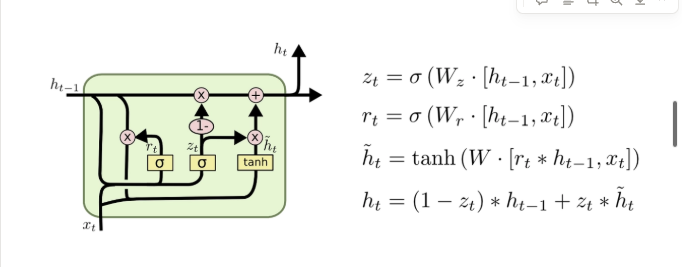  


1. **Forget gate와 Input gate를 Update gate 하나로 통합**  

- Update gate $z_t$ 하나로 '과거 기억 : 새 정보 = 몇 : 몇'을 한번에 결정  
- $h_t = (1-z_t) \odot h_{t-1} + z_t \odot \tilde{h}_t$  
- *e.g.* $z_t$ = 0.3 -> 과거 기억 70% + 새 정보 30%  

2. **Reset gate를 사용**    

- Reset gate $r_t$로 '과거 기억을 얼마나 무시할지'를 먼저 정한 뒤 후보 정보 $h_t$ 결정  
- $r_t \approx 0$ -> 과거를 거의 무시하고 현재 입력 위주로 새 정보 만듦  
- *e.g.* 문장이 끝나고 새 문장이 시작될 때, 이전 문맥을 끊고 새로 시작  

3. **Output gate가 없음**    

- 출력을 거르는 단계 없이 은닉상태 $h_t$를 그대로 출력  

4. **Gate의 개수가 3개에서 2개로 감소**   

- 파라미터가 LSTM의 약 3/4 -> 계산량이 줄어 학습시간 감소  
- 성능은 LSTM과 비슷하거나 더 좋은 경우도 존재  

#### GRU의 장단점(VS LSTM)정리  

| 구분 | 장점 (LSTM 대비) | 단점 (LSTM 대비) |
| --- | --- | --- |
| 구조 | 상태 1개, 게이트 2개로 단순 → 이해·구현이 쉬움 | 장기 기억과 출력을 분리하지 못함 |
| 속도 | 파라미터가 적어 학습이 빠르고 메모리 사용이 적음 | X |
| 데이터 | 파라미터가 적어 데이터가 적을 때도 학습이 안정적 | 데이터가 많고 복잡한 과제에서는 LSTM이 더 나을 수 있음 |
| 기억 관리 | Update gate 하나로 기억 갱신을 간단히 처리 | 잊는 양과 더하는 양을 따로 조절할 수 없어 정교함이 떨어짐 |
| 성능 | 많은 과제에서 LSTM과 비슷한 성능 | 항상 LSTM보다 낫다고 단정할 수는 없음 |  


### 4-4 LSTM vs GRU : 언제 무엇을?  

- 두 모델은 우열관계가 아닌 정교함(LSTM)과 효율(GRU)사이의 선택  
- 실제 비교 연구 및 많은 과제에서도 두 모델의 성능은 비슷  

**LSTM vs GRU 플로우차트(Flow Chart)c**  

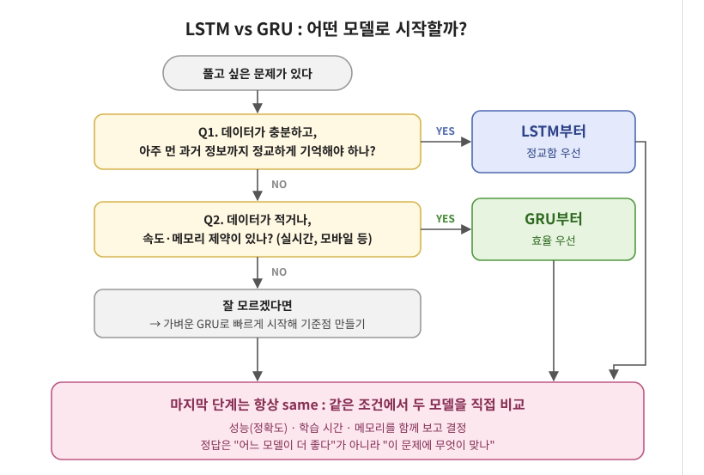  

#### *i.e.* 문제 상황따라 적합한 모델이 다르다!!!



## 5. 문장을 입력받아 문장을 출력하다 : Seq2Seq   

### 5-1 Seq2Seq의 기본 구조 : 인코더와 디코더  

> Def of Seq2Seq : 입력 시퀀스를 받아 다른 시퀀스를 출력하는 모델  
기존 RNN과 가장 큰 차이 : 입력과 출력이 서로 달라도 된다!  
- 번역의 경우 언어마다 어순도 다르고 표현시 단어 수의 차이도 존재하는데 이때 사용하는것이 바로 Seq2Seq  
- *e.g.* 'I am student' (4단어) -> 'je suis étudiant'(3단어)    

- 앞의 RNN Architecture 중 'Many to Many'를 두개의 RNN(LSTM)으로 나눠 구현한 구조  
- 활용 분야 : 기계 번역, 챗봇(질문 -> 답변), 문서 요약, 음성인식  


**Seq2Seq의 특징**  

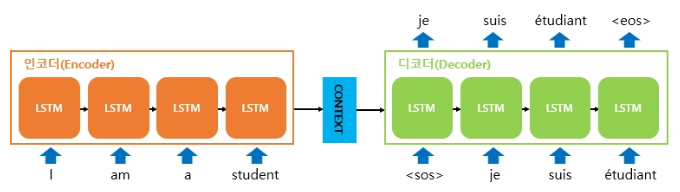  


- 인코더(Encoder)와 디코더(Decoder) 두 개의 모듈로 구성  
- 인코더 : 입력 문장을 읽고 하나의 컨텍스트 벡터로 압축  
- 컨텍스트 벡터(Context Vector) : 인코더와 디코더를 잇는 다리이자, 인코더를 거치며 압축된 정보  
- 디코더 : 컨텍스트 벡터를 받아 출력 문장을 한 단어씩 생성  
- 내부 셀로는 LSTM or GRU사용 -> 장기 의존성 문제 떄문  

=> 읽고(Encoder) -> 요약해서 넘기고(Context Vector) -> 다시 써낸다(Decoder)  


#### 인코더  

> 인코더란? 입력 문장의 모든 단어를 순서대로 읽고, 문장 전체의 정보를 하나의 벡터(컨텍스트 벡터)로 압축하는 LSTM  

**작동원리**  
1. 단어 토큰화 : 입력 문장을 단어 단위로 나눔 -> 'I', 'am', 'a', 'student'  

2. 임베딩(embedding) : 각 단어를 컴퓨터가 계산할 수 있는 숫자 벡터로 변환  

3. LSTM 셀에 한 단어씩 입력 : 매 시점 은닉 상태가 다음 시점으로 전달되며 정보가 누적됨  

4. 마지막 시점의 은닉 상태 = 문장 전체 정보가 담긴 컨텍스트 벡터 -> 디코더로 전달  

*인코더는 중간 시점의 출력은 사용하지 않고 마지막 은닉 상태인 컨벡스트 벡터만 디코더로 넘긴다!*  


#### 디코더  

> 디코더란? 컨텍스트 벡터를 받아, 출력 문장을 한 단어씩 순서대로 생성하는 LSTM   

**작동원리**  
1. 컨텍스트 벡터를 디코더 LSTM의 첫 은닉 상태로 받음 

2. 시작 신호 <sos>(start of sequence)를 첫 입력으로 넣음  

3. 매 시점 softmax로 다음 단어의 확률을 계산 → 가장 확률이 높은 단어 선택(argmax)

4. 방금 예측한 단어를 다음 시점의 입력으로 다시 넣음   
    *e.g* <sos> → 'je' → 'suis' → 'étudiant' (그림의 분홍 점선 화살표)

5. 종료 신호 <eos>(end of sequence)가 나오면 생성 종료


#### 컨텍스트 벡터

> 컨텍스트 벡터란? 인코더가 입력 문장 전체를 읽고 만든 문장 요약 벡터  
인코더 LSTM의 마지막 시점 은닉 상태 (LSTM이면 셀 상태도 함께 넘김)  
인코더와 디코더를 연결하는 유일한 통로

**차원 설정**  
- 컨텍스트 벡터의 크기 = 인코더 LSTM의 은닉 상태 크기 -> 사람이 정하는 하이퍼파라미터  

- 실제로는 보통 수백 차원 (256, 512, 1024, etc...)  

- 디코더 LSTM의 은닉 상태 크기도 같은 값으로 맞춰야 바로 이어받을 수 있음  

- 차원이 크면 더 많은 정보를 담을 수 있지만 계산량이 늘고 과적합 위험  

- 차원이 작으면 빠르지만 긴 문장의 정보를 다 담지 못함  


### 5-2 Seq2Seq의 한계 : 병목현상(Bottleneck)  

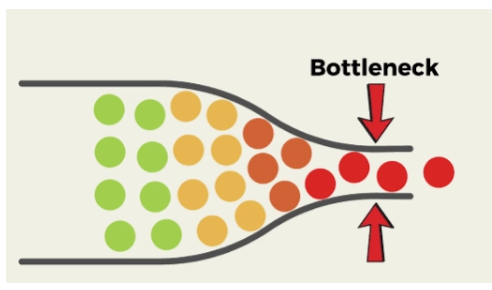  


> 병목현상? 인코더가 입력 문장 전체를 '고정된 크기의 컨텍스트 벡터 하나'에 압축하면서 정보가 좁은 통로에 막혀 손실되는 현상   


**설명**  

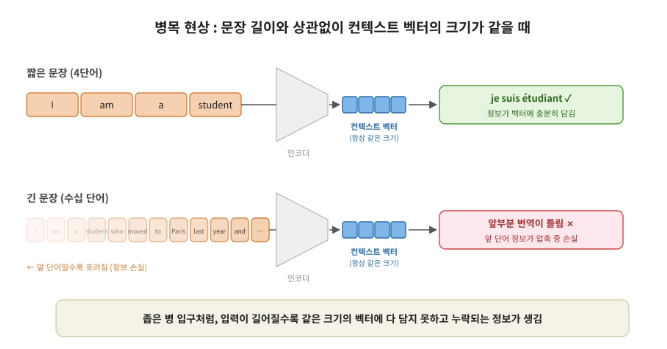  

- 단어 수의 관계 없이 같은 크기에 담아야 함 -> 긴 문장일수록 정보를 다 담지 못하고 손실되는 정보 발생  
- 앞 단어는 여러 시점을 거치며 희미해짐  -> 장기 의존성 문제 여전히 존재   

**Example**  

- 짧은 문장 : 'I am a student' -> 정보가 적어 컨텍스트 벡터에 충분히 담김 → 번역 정확  
- 긴 문장 : 'I am a student who moved to Paris last year and …' (많은 단어)
    - 같은 크기의 벡터에 담아야 해서 앞부분('I am a student')의 정보가 손실
    - 주어나 앞 내용을 틀리게 번역  


#### 결론

- 고정된 크기의 컨텍스트 벡터에 모든 정보를 압축하기 떄문에 병목현상 발생  
- 특히, 긴 입력의 시퀀스일수록 정보손실이 심각하고 모델 성능 하락  

**이러한 한계를 해결한 것이 다음 시간에 배울 ATTENTION!!!(To be continued...)**